# 06 · Electrónica, cableado y medición

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](05_csv_persistencia_y_confirmaciones.ipynb) · [Siguiente](07_pantalla_st7789.ipynb)

## GPIO, alimentación y tierra común

La tensión es una diferencia de potencial respecto de un punto de referencia. El pin de entrada mide respecto de GND de la placa. Conecta la tierra del ESP32, la de la pantalla y la de los módulos de sensor. Desconecta la alimentación antes de cambiar el cableado. Verifica la tensión de alimentación de tu módulo específico. El módulo MQ135 del montaje usa 5 V y su salida analógica pasa por un divisor antes del GPIO5.

| Componente | Señal | Conexión del proyecto |
|---|---|---|
| DHT11 | DATA digital | GPIO4 con niveles de 3.3 V. Si el módulo carece de resistencia de polarización, añade pull-up a 3.3 V. |
| MQ135 | AO analógica | GPIO5, por el punto medio de dos resistencias de 10 kΩ. |
| MQ135 | DO digital | Se deja libre. Un umbral digital no ofrece la tensión que usa la curva. |
| ST7789 | MOSI, SCLK, CS, DC, RST | GPIO13, GPIO12, GPIO10, GPIO9, GPIO8. |
| ST7789 | MISO | No conectado. |

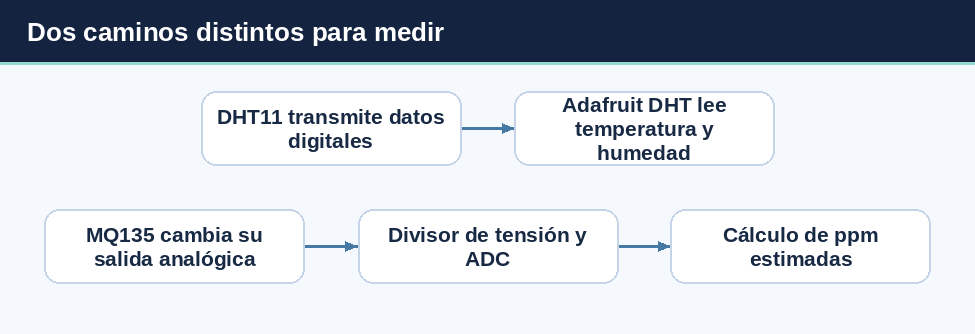

## DHT11 y humedad relativa

El DHT11 entrega datos digitales mediante pulsos. La biblioteca interpreta su temporización y devuelve valores `float`. Se usa una entrada dedicada. Una resistencia pull-up mantiene DATA en el estado alto cuando ningún componente la activa.

La humedad relativa expresa la proporción de vapor presente respecto de la saturación a la misma temperatura. Cambiar la temperatura puede cambiar la humedad relativa incluso con la misma cantidad de vapor. Por eso se reporta `%RH`. Las lecturas fallidas pueden producir `NAN` en C++, `null` en JSON y un campo vacío en CSV. Un cero sigue siendo una medición numérica.

## MQ135, divisor y conversión analógica digital

La salida AO es una tensión. El divisor de dos resistencias iguales produce cerca de la mitad de AO en la entrada de alta impedancia. El límite de tensión del pin importa aunque solo quieras detectar una lectura válida. No conectes AO de 5 V directamente al GPIO.

```text
AO del MQ135 ── R1 10 kΩ ──┬── GPIO5 (ADC)
                           │
                        R2 10 kΩ
                           │
                          GND
```

En el modelo ideal `Vadc = Vao × R2 / (R1 + R2)`. Con 10 kΩ y 10 kΩ, una AO de 3 V produciría unos 1.5 V en GPIO5. El programa estima `Vao` multiplicando por dos la media del ADC. Primero suma 32 lecturas de `analogReadMilliVolts()`. Después divide entre 32 y convierte milivoltios a voltios. Promediar reduce variación rápida de muestras individuales. Los errores sistemáticos del sensor, fuente y ADC permanecen.

La configuración de 12 bits define la representación del convertidor. En un ideal hay 4096 códigos desde 0 hasta 4095. La llamada que usa el firmware devuelve milivoltios; los códigos crudos y los milivoltios son representaciones distintas. La atenuación del ADC modifica el rango medible. El firmware rechaza rangos inválidos de tensión y evita dividir entre valores que producirían resultados inválidos.

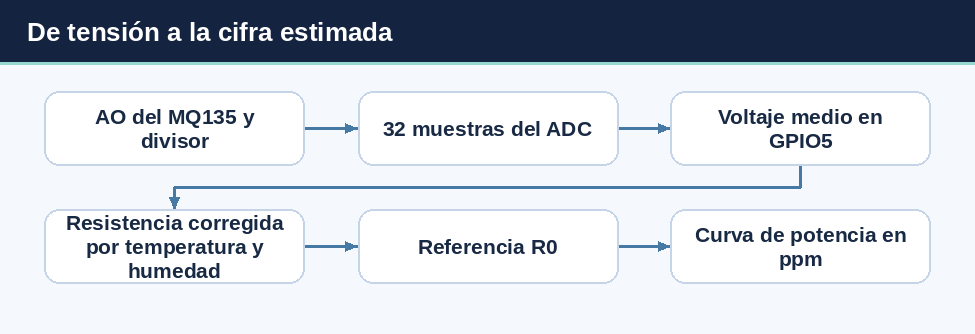

## Resistencia de carga y calibración

El modelo considera la resistencia de carga del módulo de 2 kΩ y la rama del divisor de 20 kΩ en paralelo. La carga efectiva nominal es `(2 × 20) / (2 + 20) ≈ 1.818 kΩ`. A partir de la relación `Vs / Vao` estima la resistencia sensora y aplica un factor que depende de temperatura y humedad. La función y sus constantes aparecen en `readGasPpm()`.

La curva usada es `ppm = A × (Rs / R0)^B`, con `A = 110.47` y `B = -2.862`. El signo de `B` hace que la estimación crezca cuando baja la razón `Rs / R0`. El firmware estima `R0` con 30 muestras válidas y una referencia supuesta de 450 ppm. A dos segundos por lectura, ese bloque dura alrededor de un minuto en condiciones válidas continuas, aparte del tiempo necesario para que el sensor se estabilice. Se reconstruye al reiniciar.

La referencia supuesta y la sensibilidad del MQ135 a distintos gases limitan la interpretación del dato. La salida es una estimación del montaje, con `calibrate=false`, y carece de selectividad para atribuir el valor a un gas específico. Para estudiar el comportamiento del cálculo y los datos faltantes, sigue el [capítulo de sensores](04_sensores_json_y_pantalla.ipynb).

## Ejercicios de razonamiento

1. Calcula la tensión en GPIO5 con una AO de 4 V y dos resistencias iguales.
2. Explica qué observas si el DHT11 falla y el MQ135 sigue alimentado. La estimación necesita ambas mediciones ambientales.
3. Explica por qué dos decimales en el CSV no aumentan la resolución física del sensor.
4. Compara un campo de gas vacío, una referencia en progreso y un valor de gas numérico.